# Pescadores Web: perfil e distribuição das OSCs de assistência social

**Dados reais públicos: Ipea/Mapa das OSCs (agosto/2026) e IBGE/Censo 2022.**

Pergunta: **qual é o perfil e a distribuição das OSCs de assistência social e como
os dados cadastrais podem apoiar o planejamento de parcerias do Pescadores Web?**

O recorte tem 58.184 estabelecimentos. Não contém movimentações de doações,
estoque, voluntários ou atendimentos da organização do TCC. Esta análise substitui
a demonstração anterior e não gera registros artificiais.

## Ambiente e carregamento

Execute a partir da pasta do projeto após instalar `requirements.txt`. No Colab,
o código abaixo baixa o repositório quando necessário e instala as dependências.
As fontes já incluídas são lidas do disco; o download integral é uma etapa opcional
documentada em `scripts/obter_dados.py`.

In [1]:
from pathlib import Path
import subprocess
import sys
projeto = None
for pasta in [Path.cwd(), *Path.cwd().parents]:
    for candidato in [pasta, pasta / "Projeto_ciencia_de_dados"]:
        if (candidato / "dados/brutos/FONTES.json").is_file():
            projeto = candidato
            break
    if projeto:
        break
if projeto is None:
    destino = Path.cwd() / "pescadores_repositorio"
    if not destino.exists():
        subprocess.check_call(["git", "clone", "--depth", "1",
            "https://github.com/lipefe11/Ciencia_Dados_Aprendizagem_Maquina.git", str(destino)])
    projeto = destino / "Projeto_ciencia_de_dados"
    if not (projeto / "dados/brutos/FONTES.json").is_file():
        raise FileNotFoundError("Esta versão com dados reais ainda não foi publicada na main.")
if "google.colab" in sys.modules:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","-r",str(projeto/"requirements.txt")])
sys.path.insert(0,str(projeto / "scripts"))
import analise as a
import json
import pandas as pd
from IPython.display import display, Image, Markdown
fontes = json.loads((projeto / "dados/brutos/FONTES.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{k:fontes[k] for k in ["origem","fonte_osc","fonte_populacao","linhas_original","linhas_recorte"]}]).T)


,0
origem,dados públicos observados; sem simulação
fonte_osc,https://mapaosc.ipea.gov.br/download/20260806_...
fonte_populacao,https://apisidra.ibge.gov.br/values/t/4714/n6/...
linhas_original,1113949
linhas_recorte,58184


## Fase 1 — Entendimento do negócio

O TCC Pescadores Web trata de gestão de doações, estoque e ações sociais. Esta
análise usa dados públicos de outras organizações para conhecer o contexto e
orientar uma futura verificação de parcerias, sem atribuir registros à ONG do TCC.

O [artigo HYB](https://blog.hyb.com.br/panorama-das-ongs-no-brasil-desafios-e-perspectivas-do-terceiro-setor/)
e a [publicação do IDIS](https://www.idis.org.br/panorama-das-ongs-estudo-revela-resiliencia-do-terceiro-setor-no-brasil/)
fundamentam o contexto. Os dados analisados vêm do [Ipea](https://mapaosc.ipea.gov.br/base-dados)
e do [IBGE](https://apisidra.ibge.gov.br/values/t/4714/n6/all/v/93/p/2022).

Questões: onde estão as OSCs, como comparar territórios, qual a associação com
população, quais perfis municipais aparecem e como características cadastrais se
associam à situação não ativa? Os indicadores não medem necessidade social ou capacidade.

## Fase 2 — Entendimento dos dados

O CSV oficial contém 1.113.949 CNPJs. O filtro `Area_Assistencia_social=1` seleciona
58.184 estabelecimentos, incluindo diferentes situações cadastrais. Retemos 11
colunas, sem inventar ou imputar valores. O JSON do IBGE contém metadados na primeira
linha e 5.570 municípios. Os arquivos têm URLs e hashes SHA-256 no manifesto.

O CNPJ identifica um estabelecimento: matriz e filiais não equivalem a organizações
independentes. As áreas de atuação podem se sobrepor na fonte original.

In [2]:
brutos = pd.read_csv(projeto / "dados/brutos/oscs_assistencia_social_20260806.csv",dtype=str)
print("Recorte real:", brutos.shape)
display(brutos.head())
display(brutos.situacao_cadastral.value_counts())
display(brutos.isna().sum())


Recorte real: (58184, 11)


,cnpj,tx_razao_social_osc,natureza_juridica,matriz_filial,situacao_cadastral,dt_fundacao_osc,removida_do_mosc,cd_municipio,municipio_nome,UF_Sigla,Area_Assistencia_social
0,72431042000198,ASSOCIACAO DE MORADORES TERRA NOVA,3999,Matriz,Inapta,1993-07-07,não,4125605,S�O MATEUS DO SUL,PR,1
1,00542687000197,ASSOCIACAO COMUNITARIA DOS MORADORES DA BEIRA ...,3999,Matriz,Inapta,1995-03-23,não,2111003,S�O JO�O BATISTA,MA,1
2,00533275000190,AS DOS ATIN P ADUT DO SER DO M P CAN IR DO V D...,3999,Matriz,Inapta,1995-03-30,não,2702405,DELMIRO GOUVEIA,AL,1
3,01014938000123,ASSOCIACAO DE PAIS E AMIGOS DE CRIANCAS ESPEC....,3999,Matriz,Inapta,1996-01-19,não,2804607,NOSSA SENHORA DAS DORES,SE,1
4,01523284000163,ASSOCIACAO DE APOIO P/ DEPEND DO ALCOOL E OUTR...,3999,Matriz,Ativa,1996-11-07,não,4128203,UNI�O DA VIT�RIA,PR,1


situacao_cadastral
Ativa              40219
Inapta             14270
Nula ou Baixada     3336
Suspensa             359
Name: count, dtype: int64

cnpj                        0
tx_razao_social_osc         0
natureza_juridica           4
matriz_filial               0
situacao_cadastral          0
dt_fundacao_osc             4
removida_do_mosc            0
cd_municipio                0
municipio_nome             14
UF_Sigla                   14
Area_Assistencia_social     0
dtype: int64

## Fase 3 — Preparação

Verificar CNPJ, duplicatas, datas e UFs. Preservar as observações originais nos
arquivos brutos. Nomes municipais corrompidos não são reconstruídos por palpite:
o cruzamento usa códigos e os nomes oficiais do IBGE.

Ativa no Mapa = situação Ativa e não removida. Datas ausentes são excluídas da
modelagem, sem preenchimento. Municípios do Censo sem OSC ativa recebem contagem
zero; idades e frações não são imputadas. O numerador cadastral é de 2026 e a
população é de 2022: a taxa resultante não é uma taxa oficial de 2026.

In [3]:
osc, municipios, qualidade, fontes = a.preparar(projeto)
display(qualidade)
display(municipios.head())
print("OSCs ativas e não removidas:", int(osc.ativa_no_mapa.sum()))
consultas = a.sql(osc, municipios, projeto)
for nome, resultado in consultas.items():
    print(nome)
    display(resultado.head(8))


,verificacao,ocorrencias
0,cnpj_invalido,0
1,cnpj_duplicado,0
2,data_fundacao_ausente_ou_invalida,4
3,fundacao_posterior_referencia,0
4,uf_invalida,14
5,nome_municipio_com_caractere_substituido,24879
6,oscs_ativas_sem_correspondencia_municipal_cens...,0


,cd_municipio,municipio,populacao_2022,uf,oscs_ativas,idade_mediana,fracao_fundadas_2010,oscs_por_100mil
0,1100015,Alta Floresta D'Oeste - RO,21494,RO,3,22.899384,0.333333,13.957383
1,1100023,Ariquemes - RO,96833,RO,24,22.487337,0.333333,24.784939
2,1100031,Cabixi - RO,5351,RO,2,11.561944,1.000000,37.376191
3,1100049,Cacoal - RO,86887,RO,17,25.295003,0.294118,19.565643
4,1100056,Cerejeiras - RO,15890,RO,11,33.587953,0.181818,69.225928


OSCs ativas e não removidas: 39836


01_situacao_cadastral


,situacao_cadastral,estabelecimentos
0,Ativa,40219
1,Inapta,14270
2,Nula ou Baixada,3336
3,Suspensa,359


02_ativas_por_uf


... (9 outputs left out)

07_integridade


,linhas,cnpjs_distintos,datas_futuras
0,58184,58184,0


08_faixas_idade


,faixa,oscs_ativas
0,01: menos de 10,8049
1,02: 10 a 19,7639
2,03: 20 a 29,8260
3,04: 30 ou mais,15888


### Dispersão e regressão linear

Municípios são as observações. Ajuste `ln(1 + OSCs ativas)` em função de
`log10(população 2022)`. Separação municipal 80% treino e 20% teste, semente 42.
Reportar R² na escala log e MAE da contagem após transformação inversa. A associação
é transversal, sem demonstrar causalidade ou prever aumento futuro de OSCs.

In [4]:
reg = a.regressao(municipios, projeto)
display(pd.DataFrame([reg[3]]))


,coeficiente,intercepto,r2_teste_log,mae_teste_oscs,n_treino,n_teste
0,1.66592,-5.660088,0.595034,3.521388,4456,1114


## Fase 4 — Modelagem

### K-means

Municípios com ao menos cinco OSCs ativas. Padronizar densidade em log, idade
mediana e fração fundada desde 2010. Comparar k = 2, 3, 4 e 5 pela silhueta.
Os grupos são exploratórios, sem rótulos de carência, eficiência ou impacto.

In [5]:
perfis, avaliacao_k = a.agrupar(municipios, projeto)
display(avaliacao_k)
display(perfis.groupby("cluster").agg(municipios=("cd_municipio","count"),
    idade_mediana=("idade_mediana","median"),densidade_mediana=("oscs_por_100mil","median")))


,k,silhueta
0,2,0.359945
1,3,0.311083
2,4,0.284967
3,5,0.285301


,municipios,idade_mediana,densidade_mediana
cluster,,,
0,641,19.943874,19.993145
1,850,31.134839,33.142053


### Classificação cadastral

Alvo positivo: situação diferente de Ativa. Variáveis: idade cadastral, UF e
natureza jurídica. Excluir remoção, fechamento, razão social, CNAE e matriz/filial
dos preditores. **A situação observada já está na fonte**: o modelo é exercício
metodológico, não substitui consulta cadastral nem prevê saúde financeira.

Separar por raiz do CNPJ para que matriz e filiais não atravessem treino, validação
e teste. Escolher por F1 na validação (limiar 0,5), reajustar em treino + validação
e avaliar o teste apenas depois. Não se trata de avaliação temporal.

In [6]:
treino, validacao, teste = a.dividir(osc)
display(pd.DataFrame([{"conjunto":n,"linhas":len(f),"grupos":f.cnpj_raiz.nunique(),"fracao_nao_ativa":f.nao_ativa.mean()}
    for n,f in [("treino",treino),("validacao",validacao),("teste",teste)]]))
metricas_val, metricas_teste, escolhido, pred = a.modelar(osc, projeto)
display(metricas_val)
print("Modelo selecionado antes do teste:",escolhido)


,conjunto,linhas,grupos,fracao_nao_ativa
0,treino,37228,32490,0.309713
1,validacao,9265,8123,0.315704
2,teste,11673,10154,0.300180


,modelo,acuracia,precisao,recall,f1,auc_roc,ap
0,Maioria,0.684296,0.000000,0.000000,0.000000,0.500000,0.315704
1,Regressao logistica,0.570426,0.364151,0.483419,0.415394,0.554891,0.367989
2,Arvore,0.553157,0.400099,0.831795,0.540306,0.662127,0.422773
3,Random Forest,0.554992,0.399530,0.814359,0.536064,0.658589,0.444167


Modelo selecionado antes do teste: Arvore


## Fase 5 — Avaliação

Precisão: positivos previstos que se confirmam. Recall: não ativas identificadas.
F1 combina ambos; a classe majoritária pode ter acurácia alta e F1 zero. AP é
average precision. Modelos limitados não devem ser apresentados como solução
pronta para selecionar ou rejeitar parcerias.

,modelo,acuracia,precisao,recall,f1,auc_roc,ap
0,Maioria,0.699820,0.000000,0.000000,0.000000,0.500000,0.300180
1,Regressao logistica,0.569605,0.338915,0.456336,0.388956,0.550408,0.342634
2,Arvore,0.551786,0.387646,0.850742,0.532607,0.678264,0.420820
3,Random Forest,0.549730,0.384524,0.832477,0.526060,0.668320,0.428743


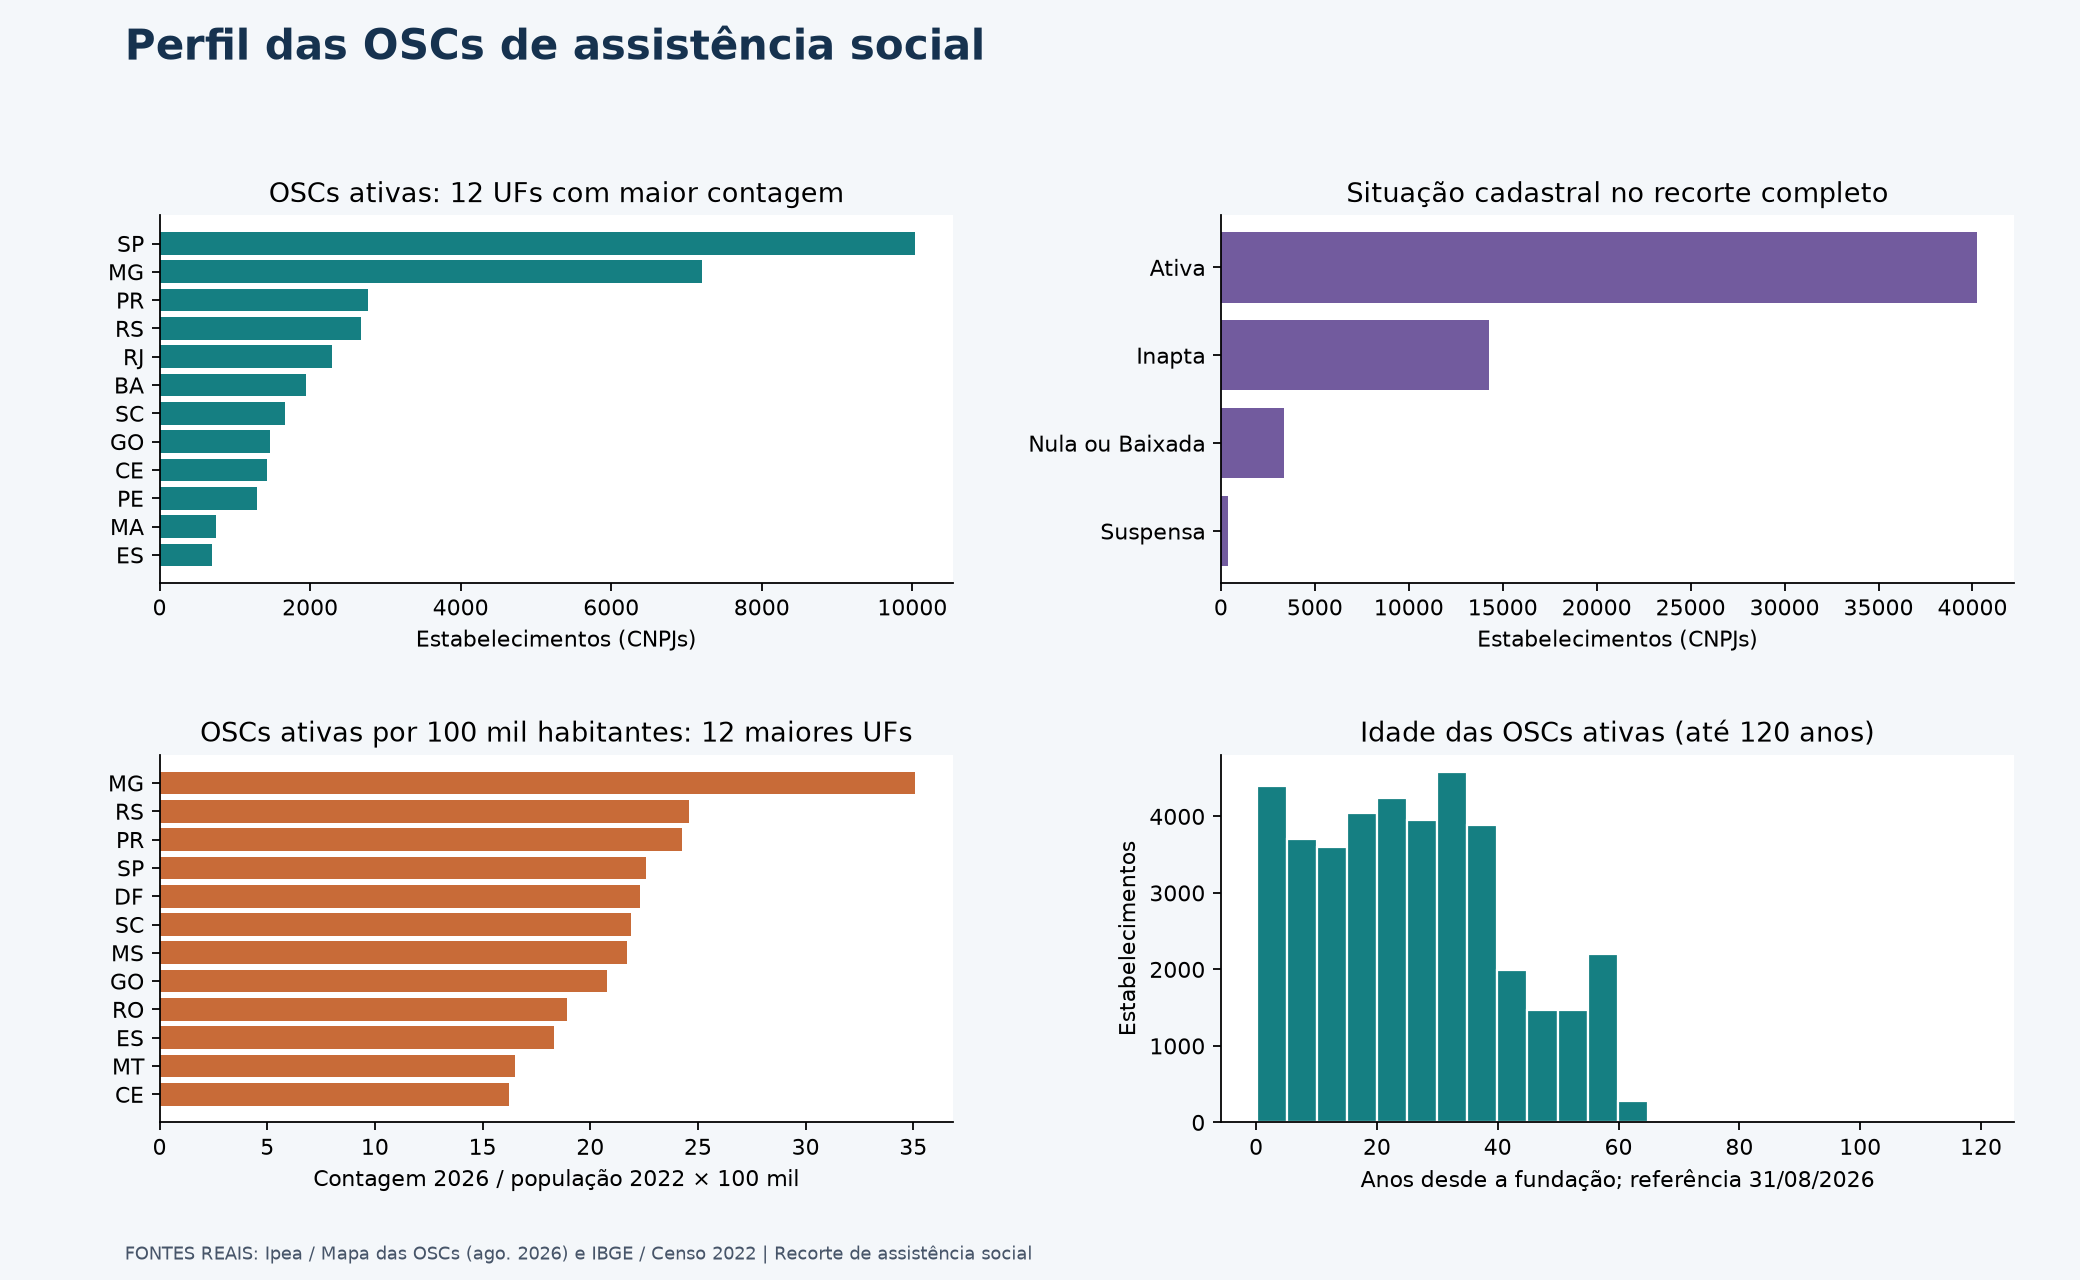

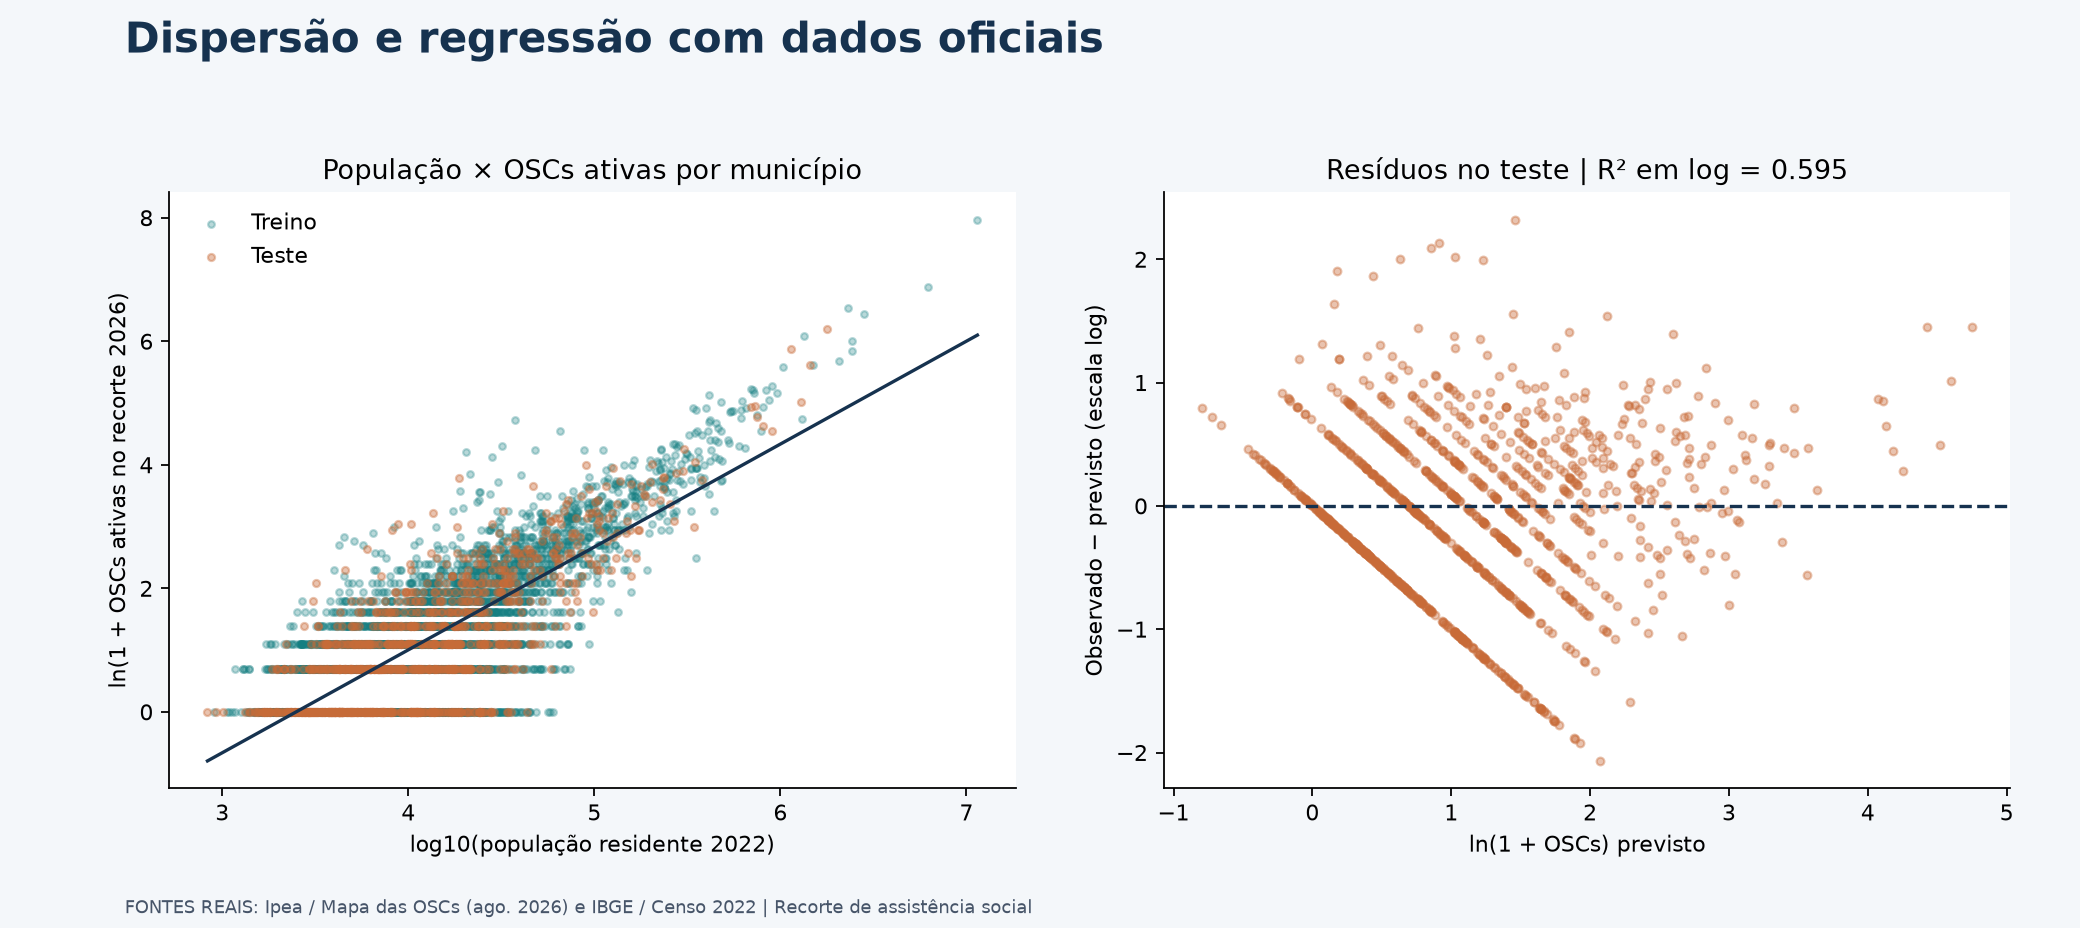

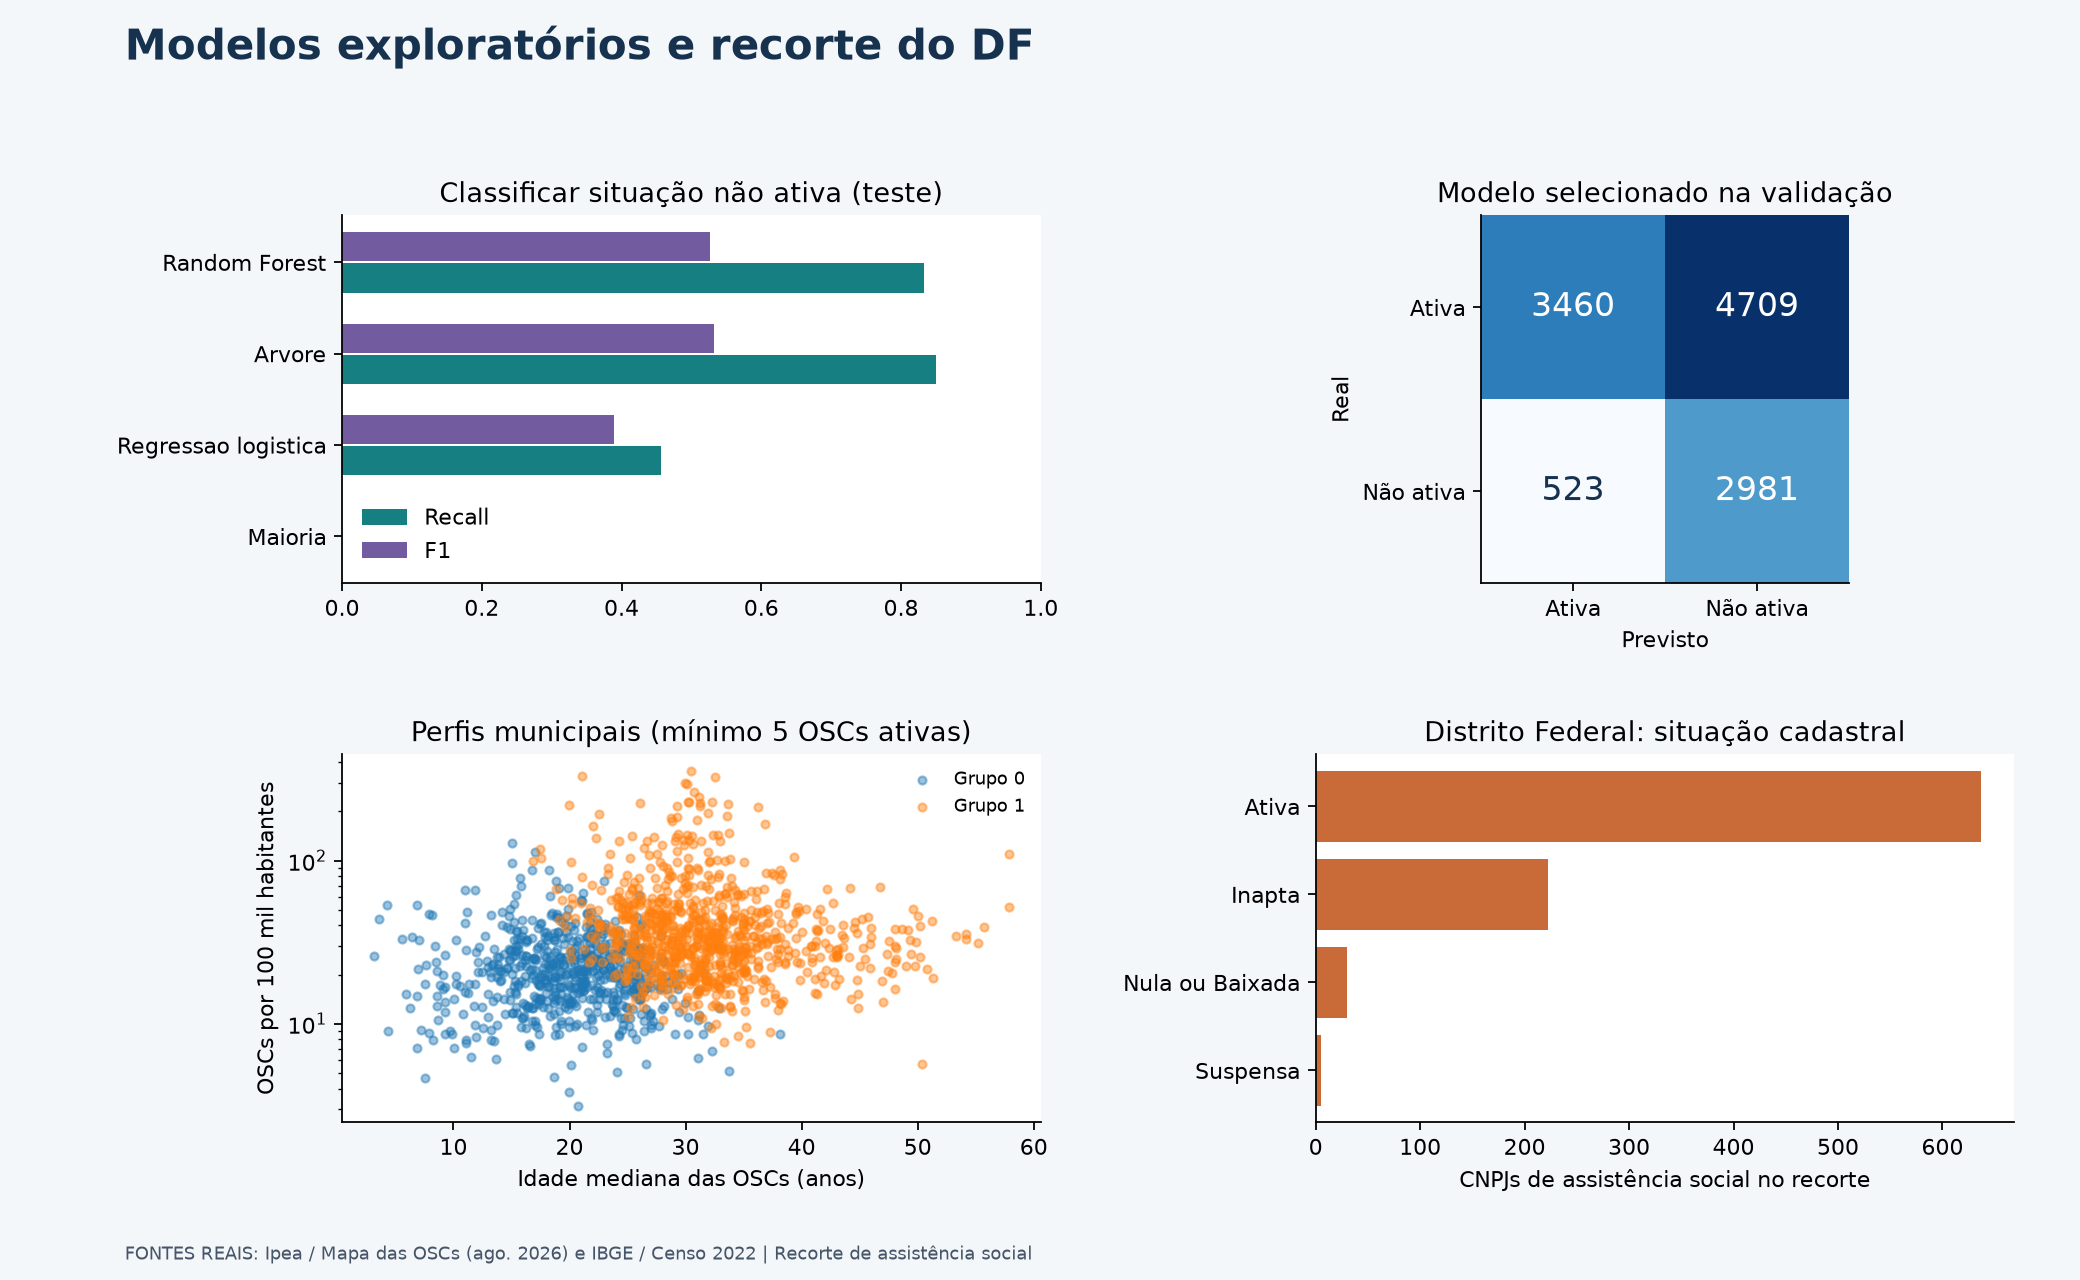

In [7]:
display(metricas_teste)
a.graficos(osc, municipios, metricas_teste, pred, perfis, reg, projeto)
for nome in ["01_visao_geral.png","02_dispersao_regressao.png","03_modelos.png"]:
    display(Image(filename=str(projeto / "Dashboard" / nome)))


## Fase 6 — Implementação proposta

O painel pode contextualizar a distribuição do setor e preparar uma lista de OSCs
para verificação. Confirmar a situação cadastral e o funcionamento diretamente nas
fontes antes de uma parceria. Não há integração ao Laravel ou contato automático.

Monitorar atualização das fontes, hashes, completude, junções municipais e mudança
das distribuições. Na próxima iteração, atualizar os anos de referência e obter
registros operacionais reais se o objetivo voltar a ser doações ou estoque.

Zero no recorte não prova ausência de assistência; contagem não mede necessidade
ou capacidade. O Censo e a base de OSCs têm datas diferentes.

In [8]:
resumo = a.relatar(osc, municipios, qualidade, fontes, metricas_val, metricas_teste,
    escolhido, perfis, avaliacao_k, reg, projeto)
display(Markdown((projeto / "resultados/RESULTADOS.md").read_text(encoding="utf-8")))


# Resultados com dados públicos reais

Pergunta: qual é o perfil e a distribuição das OSCs de assistência social e como os
dados cadastrais podem apoiar o planejamento de parcerias do Pescadores Web?

## Fontes e recortes

Ipea/Mapa das OSCs: arquivo oficial 20260806, coleta agosto/2026 conforme portal.
IBGE: Censo 2022, população residente municipal, SIDRA tabela 4714, variável 93.
Extração em 4/11/2026. A fonte integral tem 1,113,949 CNPJs;
o filtro Area_Assistencia_social = 1 resulta em 58,184 estabelecimentos.
Há 39,836 CNPJs com situação Ativa e não removidos do Mapa.
São CNPJs de estabelecimentos, incluindo filiais, não necessariamente instituições
independentes. As áreas de atuação podem se sobrepor na base original.

O arquivo integral (343 MB) fica fora do repositório; o recorte exato de linhas e
colunas está em dados/brutos. URLs, filtros e hashes SHA-256 estão em FONTES.json.
Não há observações artificiais, erros inseridos ou preenchimento de valores faltantes
das OSCs. Zeros municipais são contagens obtidas após o cruzamento, não OSCs inventadas.

## Qualidade

| verificacao | ocorrencias |
| --- | --- |
| cnpj_invalido | 0 |
| cnpj_duplicado | 0 |
| data_fundacao_ausente_ou_invalida | 4 |
| fundacao_posterior_referencia | 0 |
| uf_invalida | 14 |
| nome_municipio_com_caractere_substituido | 24879 |
| oscs_ativas_sem_correspondencia_municipal_censo2022 | 0 |

O nome municipal do Ipea contém caracteres substituídos em parte das linhas.
Não reconstruímos grafias por palpite: agregações usam código municipal e os nomes
do IBGE. Datas inválidas/futuras ficam fora da modelagem. Linhas sem vínculo municipal
são registradas em sem_correspondencia.csv; não são redistribuídas.

## Distribuição e relação com a população

Dos 5570 municípios/territórios municipais retornados pelo Censo,
3954 têm ao menos uma OSC ativa no recorte. O DF tem
894 estabelecimentos no recorte completo, somando situações cadastrais.
As taxas relacionam numerador 2026 a denominador 2022: não são taxas oficiais de
2026. Contagem e densidade não medem capacidade de atendimento nem necessidade social.

Regressão: ln(1 + OSCs ativas) = 1.6659 × log10(população 2022)
+ -5.6601. Treino: 4456 municípios; teste:
1114. R² no teste em escala log: 0.595; MAE na
escala de contagem após transformação inversa: 3.52 OSCs.
No cálculo do MAE, previsões invertidas negativas são limitadas a zero. O gráfico
mostra a reta linear bruta; ela pode extrapolar valores negativos para municípios
pequenos. Modelos próprios para contagens são uma alternativa para a próxima etapa.
É associação transversal, sem causalidade ou previsão de crescimento futuro.

## Classificação cadastral

Alvo positivo: situação diferente de Ativa (Inapta, Suspensa ou Nula ou Baixada).
Características: idade cadastral, UF e natureza jurídica. Situação, remoção,
fechamento, razão social, CNAE e marcador matriz/filial não entram nas características.
É uma demonstração de associação cadastral; a situação real já está disponível
na fonte e deve ser consultada diretamente, sem substituir o cadastro por previsão.

Divisão por raiz do CNPJ (8 dígitos): 37228 treino, 9265 validação e 11673
teste, com 3504 positivos. Matriz e filiais não atravessam partições.
Não é teste temporal e não valida previsão de encerramento ou dificuldade financeira.
Modelo escolhido por F1 na validação, antes de usar o teste: **Arvore**.

Validação:

| modelo | acuracia | precisao | recall | f1 | auc_roc | ap |
| --- | --- | --- | --- | --- | --- | --- |
| Maioria | 0.684 | 0.000 | 0.000 | 0.000 | 0.500 | 0.316 |
| Regressao logistica | 0.570 | 0.364 | 0.483 | 0.415 | 0.555 | 0.368 |
| Arvore | 0.553 | 0.400 | 0.832 | 0.540 | 0.662 | 0.423 |
| Random Forest | 0.555 | 0.400 | 0.814 | 0.536 | 0.659 | 0.444 |

Teste após reajuste em treino + validação:

| modelo | acuracia | precisao | recall | f1 | auc_roc | ap |
| --- | --- | --- | --- | --- | --- | --- |
| Maioria | 0.700 | 0.000 | 0.000 | 0.000 | 0.500 | 0.300 |
| Regressao logistica | 0.570 | 0.339 | 0.456 | 0.389 | 0.550 | 0.343 |
| Arvore | 0.552 | 0.388 | 0.851 | 0.533 | 0.678 | 0.421 |
| Random Forest | 0.550 | 0.385 | 0.832 | 0.526 | 0.668 | 0.429 |

Precisão mede a fração de positivos previstos que se confirmam; recall mede a fração
dos não ativos identificados. AP é average precision. O limiar é fixo em 0,5.
Os resultados têm utilidade didática e não justificam negar parcerias ou atribuir
falhas operacionais a uma organização.

## K-means e aplicação ao TCC

1491 municípios com pelo menos cinco OSCs ativas são agrupados por densidade
(log), idade mediana e fração fundada desde 2010. k = 2, silhueta =
0.360. Grupos são exploratórios, sem rótulos de carência ou impacto.

O Pescadores Web pode usar os indicadores para conhecer o contexto territorial e
preparar uma lista de organizações a verificar. O painel pode ser incorporado como
contextualização; não contém doações, estoque, voluntários ou atendimentos da ONG.
Não há integração automática ao Laravel nem mensagens enviadas às organizações.

## Limitações e próxima etapa

Cadastro não comprova funcionamento, capacidade, saúde financeira ou qualidade do
serviço. Há diferença entre datas das fontes, possibilidade de desatualização e
variação de cobertura. Zero no recorte não prova ausência de assistência social.
As divisões aleatórias por grupo não eliminam dependência regional. Revalidar os
indicadores quando a base mudar, guardar os hashes e confirmar informações antes
de estabelecer uma parceria. Para analisar falta de estoque serão necessários
registros operacionais reais; essa previsão foi retirada desta versão.


## Referências

URLs, datas, filtro e hashes: `dados/brutos/FONTES.json`. Referências completas:
`docs/REFERENCIAS.md`. Campos e regras: `docs/DICIONARIO_DADOS.md`.
Nenhuma observação da análise foi produzida por simulação.